In [1]:
import sys
sys.path.append("..")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

money_columns = ["id", "funded_amnt", "total_pymnt"]


def load_with_profit(split):
    predictions = pd.read_parquet(f"../data/processed/{split}_predictions.parquet")
    loans = pd.read_parquet(f"../data/processed/{split}.parquet", columns=money_columns)
    data = predictions.merge(loans, on="id", how="inner")
    data["profit"] = data["total_pymnt"] - data["funded_amnt"]
    return data


valid = load_with_profit("valid")
test = load_with_profit("test")

print("Validation loans:", len(valid), "| Test loans:", len(test))

Validation loans: 120790 | Test loans: 162236


In [2]:
summary = valid.groupby("target")["profit"].agg(["count", "mean", "sum"])
summary.index = ["Repaid (0)", "Defaulted (1)"]
summary["sum_millions"] = summary["sum"] / 1e6
print("Approve everyone, total profit: $", round(valid["profit"].sum() / 1e6, 2), "million")
summary.round(0)

Approve everyone, total profit: $ 105.23 million


,count,mean,sum,sum_millions
Repaid (0),102521,1840.0,188665218.0,189.0
Defaulted (1),18269,-4567.0,-83430898.0,-83.0


In [3]:
def policy_curve(data, probability_column, thresholds):
    rows = []
    for t in thresholds:
        approved = data[probability_column] < t
        rows.append({
            "threshold": t,
            "approval_rate": approved.mean(),
            "default_rate_approved": data.loc[approved, "target"].mean(),
            "profit": data.loc[approved, "profit"].sum(),
        })
    return pd.DataFrame(rows)


thresholds = np.round(np.arange(0.05, 0.605, 0.005), 3)
curve_lgbm = policy_curve(valid, "p_lgbm", thresholds)
curve_logistic = policy_curve(valid, "p_logistic", thresholds)

approve_all_valid = valid["profit"].sum()
best = curve_lgbm.loc[curve_lgbm["profit"].idxmax()]

print(f"Approve everyone:   ${approve_all_valid / 1e6:.2f} million")
print(f"Best cut-off:       {best['threshold']:.3f}")
print(f"Profit at best:     ${best['profit'] / 1e6:.2f} million")
print(f"Approval rate:      {best['approval_rate'] * 100:.1f}%")
print(f"Default rate among approved: {best['default_rate_approved'] * 100:.1f}%")

Approve everyone:   $105.23 million
Best cut-off:       0.360
Profit at best:     $106.56 million
Approval rate:      96.9%
Default rate among approved: 14.4%


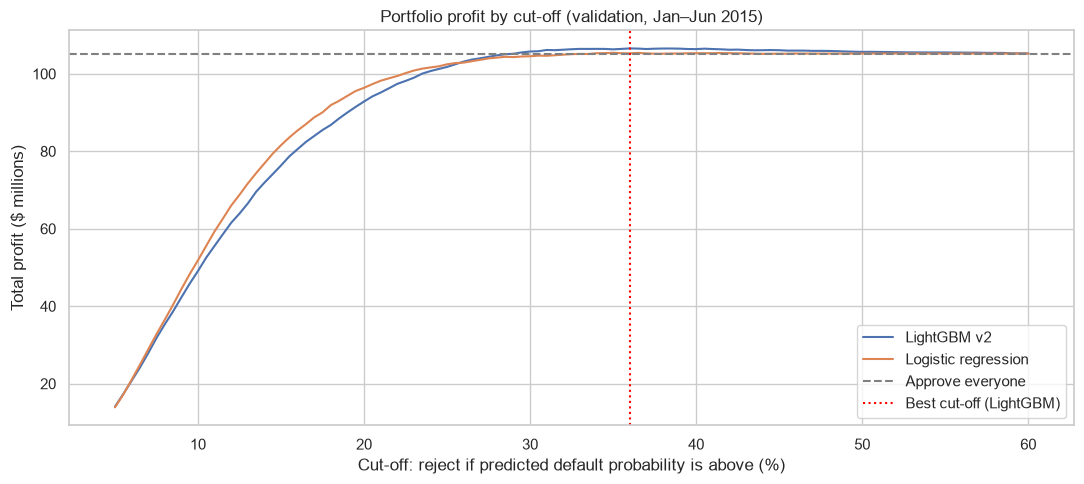

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(curve_lgbm["threshold"] * 100, curve_lgbm["profit"] / 1e6, label="LightGBM v2")
ax.plot(curve_logistic["threshold"] * 100, curve_logistic["profit"] / 1e6, label="Logistic regression")
ax.axhline(approve_all_valid / 1e6, color="gray", linestyle="--", label="Approve everyone")
ax.axvline(best["threshold"] * 100, color="red", linestyle=":", label="Best cut-off (LightGBM)")
ax.set_xlabel("Cut-off: reject if predicted default probability is above (%)")
ax.set_ylabel("Total profit ($ millions)")
ax.set_title("Portfolio profit by cut-off (validation, Jan–Jun 2015)")
ax.legend()

plt.tight_layout()
plt.savefig("../results/figures/profit_by_cutoff_validation.png", dpi=120)
plt.show()

In [5]:
t = best["threshold"]
rejected = valid[valid["p_lgbm"] >= t]

losses_avoided = -rejected.loc[rejected["target"] == 1, "profit"].sum()
profit_given_up = rejected.loc[rejected["target"] == 0, "profit"].sum()

print(f"Rejected loans: {len(rejected):,}")
print(f"  of which defaulted: {(rejected['target'] == 1).sum():,}")
print(f"  of which repaid:    {(rejected['target'] == 0).sum():,}")
print(f"Losses avoided (rejected defaulters):  ${losses_avoided / 1e6:.2f} million")
print(f"Profit given up (rejected good loans): ${profit_given_up / 1e6:.2f} million")
print(f"Net gain vs approving everyone:        ${(losses_avoided - profit_given_up) / 1e6:.2f} million")

Rejected loans: 3,762
  of which defaulted: 1,474
  of which repaid:    2,288
Losses avoided (rejected defaulters):  $7.82 million
Profit given up (rejected good loans): $6.50 million
Net gain vs approving everyone:        $1.32 million


In [6]:
t = best["threshold"]

def apply_policy(data, probability_column, cutoff):
    approved = data[probability_column] < cutoff
    return {
        "approval_rate_pct": approved.mean() * 100,
        "default_rate_approved_pct": data.loc[approved, "target"].mean() * 100,
        "profit_millions": data.loc[approved, "profit"].sum() / 1e6,
    }

best_logistic_t = curve_logistic.loc[curve_logistic["profit"].idxmax(), "threshold"]

test_policy = pd.DataFrame({
    "Approve everyone": apply_policy(test, "p_lgbm", 1.01),
    "Logistic regression policy": apply_policy(test, "p_logistic", best_logistic_t),
    "LightGBM policy": apply_policy(test, "p_lgbm", t),
}).T

test_policy["gain_vs_approve_all"] = (
    test_policy["profit_millions"] - test_policy.loc["Approve everyone", "profit_millions"]
)

print(f"LightGBM cut-off (chosen on validation): {t:.3f}")
print(f"Logistic cut-off (chosen on validation): {best_logistic_t:.3f}")
test_policy.round(2)

LightGBM cut-off (chosen on validation): 0.360
Logistic cut-off (chosen on validation): 0.350


,approval_rate_pct,default_rate_approved_pct,profit_millions,gain_vs_approve_all
Approve everyone,100.00,14.71,132.20,0.00
Logistic regression policy,98.45,14.32,132.81,0.61
LightGBM policy,97.18,13.95,134.75,2.55


In [7]:
from src.policy import decide

REVIEW_MARGIN = 0.03

test["decision"] = test["p_lgbm"].apply(lambda p: decide(p, t, REVIEW_MARGIN))

decision_summary = test.groupby("decision").agg(
    loans=("id", "count"),
    default_rate=("target", "mean"),
    avg_probability=("p_lgbm", "mean"),
)
decision_summary["share_pct"] = decision_summary["loans"] / len(test) * 100
decision_summary["default_rate"] = decision_summary["default_rate"] * 100
decision_summary.loc[["Approve", "Review", "Reject"]].round(2)

,loans,default_rate,avg_probability,share_pct
decision,,,,
Approve,154952,13.61,0.13,95.51
Review,2714,33.31,0.34,1.67
Reject,4570,40.79,0.42,2.82


In [8]:
policy = {
    "model": "lightgbm_v2_calibrated",
    "cutoff": float(t),
    "review_margin": REVIEW_MARGIN,
    "chosen_on": "validation (2015-01 to 2015-06)",
}
with open("../results/policy.json", "w") as f:
    json.dump(policy, f, indent=2)
print(policy)

{'model': 'lightgbm_v2_calibrated', 'cutoff': 0.36, 'review_margin': 0.03, 'chosen_on': 'validation (2015-01 to 2015-06)'}


In [9]:
test_policy.to_csv("../results/policy_test_results.csv")
test_policy.round(2)

,approval_rate_pct,default_rate_approved_pct,profit_millions,gain_vs_approve_all
Approve everyone,100.00,14.71,132.20,0.00
Logistic regression policy,98.45,14.32,132.81,0.61
LightGBM policy,97.18,13.95,134.75,2.55
